# Projection bake-off: does anything beat the plain Sleeper projection?

Re-runs the SPEC section 5 comparison on the saved fixture in `reference/fixture/` (one full live pull) with a
**rolling origin**: for every held-out week, train on earlier weeks only and predict it. Candidates ported from
`reference/sleeper_model.ipynb`:

1. **projection**: Sleeper's (Rotowire) weekly projection, scored with the league's own scoring settings.
2. **residual_gbm**: projection + 0.3 × a gradient-boosted correction of the projection's residual.
3. **shrink_to_avg**: projection shrunk toward the player's season average, weight `gp / (gp + 10)`.
4. **gbm**: gradient boosting on form, snap share and matchup grade.

The original run (weeks 4 and 5 held out) gave MAE 4.39 / 4.43 / 4.47 / 4.68 in that order. Rule: if the plain
projection does not win, say so; nothing here is tuned to make it win.

In [1]:
import gzip, json, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

pd.set_option('display.width', 140)
FIX = Path('..') / 'reference' / 'fixture'          # relative to this notebook
manifest = json.load(open(FIX / 'manifest.json'))
LEAGUE_ID, SEASON, USER_ID = manifest['league_id'], manifest['season'], manifest['user_id']
URLS = manifest['files']                              # full URL -> file name

def fx(url_ok):
    """Parsed JSON of the single fixture file whose URL satisfies url_ok."""
    hits = [f for u, f in URLS.items() if url_ok(u)]
    assert len(hits) == 1, hits
    with gzip.open(FIX / hits[0], 'rt') as fh:
        return json.load(fh)

league = fx(lambda u: u.endswith(f'/v1/league/{LEAGUE_ID}'))
state = fx(lambda u: u.endswith('/v1/state/nfl'))
schedule = fx(lambda u: '/schedule/nfl/regular/' in u)
SC = league['scoring_settings']
CUR = int(state['week'])
stat_weeks = sorted(int(m.group(1)) for u in URLS if (m := re.search(rf'/v1/stats/nfl/regular/{SEASON}/(\d+)$', u)))
proj_weeks = sorted(int(m.group(1)) for u in URLS if (m := re.search(rf'/projections/nfl/{SEASON}/(\d+)\?', u)))
print(league['name'], '| league', LEAGUE_ID, '| season', SEASON, '| current week', CUR)
print('stats weeks      ', stat_weeks)
print('projection weeks ', proj_weeks)

fantasy | league 1392645750013329408 | season 2026 | current week 6
stats weeks       [1, 2, 3, 4, 5, 6]
projection weeks  [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


## Scoring with the league's settings

Same rules as `makeScorer` in `src/engine/model.ts`: pick the PPR / half / standard column by `rec`, adjust for
passing-TD points relative to the 4-point default, and add the TE / WR / RB catch bonuses. The same function scores
both the actual stat lines and the projections, so the comparison is apples to apples.

In [2]:
def make_scorer(sc):
    rec = sc.get('rec', 1)
    base = 'pts_ppr' if rec >= 0.75 else 'pts_half_ppr' if rec >= 0.25 else 'pts_std'
    pass_td = sc.get('pass_td', 4) - 4
    bonus = [(k, sc[k]) for k in ('bonus_rec_te', 'bonus_rec_wr', 'bonus_rec_rb') if sc.get(k)]
    def score(st):
        if not st: return 0.0
        v = st.get(base) if st.get(base) is not None else st.get('pts_ppr', 0)
        if pass_td and st.get('pass_td'): v += pass_td * st['pass_td']
        for k, w in bonus:
            if st.get(k): v += w * st[k]
        return v
    return score
score = make_scorer(SC)
print('rec =', SC.get('rec', 1), '| pass_td =', SC.get('pass_td', 4), '| catch bonuses:', {k: SC[k] for k in SC if k.startswith('bonus_rec')})

rec = 1 | pass_td = 4 | catch bonuses: {}


## Load the weeks

* **Positions and teams** come from the projection rows' embedded player records (latest week first), as in the
  app's engine. Team defenses are keyed by their team code.
* **Actual points** exist only for players with `gms_active`.
* **Snap share** is `off_snp / tm_off_snp` from the Sleeper weekly stats.
* The fixture has projections from week 2, so week 1 has actuals but no projections and cannot be a test or training
  row. Opponents come from the projection row, falling back to the NFL schedule.

In [3]:
stats = {w: fx(lambda u, w=w: u.endswith(f'/v1/stats/nfl/regular/{SEASON}/{w}')) for w in stat_weeks}
proj = {}
for w in proj_weeks:
    rows = fx(lambda u, w=w: f'/projections/nfl/{SEASON}/{w}?' in u)
    proj[w] = {r['player_id']: r for r in rows}

info = {}
for w in sorted(proj, reverse=True):
    for pid, r in proj[w].items():
        if pid in info: continue
        pl = r.get('player') or {}
        info[pid] = dict(pos=pl.get('position') or ('DEF' if pid.isalpha() else None), team=pl.get('team') or r.get('team'))
POS = ['QB', 'RB', 'WR', 'TE', 'K', 'DEF']
POSI = {p: i for i, p in enumerate(POS)}

sched_opp = {}
for g in schedule:
    sched_opp.setdefault(g['week'], {})[g['home']] = g['away']; sched_opp[g['week']][g['away']] = g['home']

def pts(w, pid):
    s = stats[w].get(pid)
    return score(s) if s and s.get('gms_active') else None
def proj_pts(w, pid):
    r = proj.get(w, {}).get(pid)
    return score(r['stats']) if r else None
def opp_of(w, pid):
    r = proj.get(w, {}).get(pid)
    if r and r.get('opponent'): return r['opponent']
    return sched_opp.get(w, {}).get(info.get(pid, {}).get('team'))
print({w: len(stats[w]) for w in stats})

{1: 2331, 2: 2352, 3: 2357, 4: 2386, 5: 2241, 6: 149}


## Which weeks are complete?

Week 6 is the week the fixture was captured in. A week counts as complete only if **every** NFL game that week has
status `complete` in the saved schedule. Incomplete weeks have partial actuals (only games already played), which would
bias an error measure, so they are excluded from evaluation.

In [4]:
status = pd.DataFrame(schedule).groupby('week').status.agg(n_games='size', n_complete=lambda s: (s == 'complete').sum())
status['complete'] = status.n_complete == status.n_games
status = status.loc[sorted(set(stat_weeks) | set(proj_weeks))]
status['has_stats'] = status.index.isin(stat_weeks); status['has_proj'] = status.index.isin(proj_weeks)
status['players_with_actuals'] = [sum(1 for s in stats.get(w, {}).values() if s.get('gms_active')) for w in status.index]
status.loc[status.index <= CUR]

,n_games,n_complete,complete,has_stats,has_proj,players_with_actuals
week,,,,,,
1,16,16,True,True,False,2263
2,16,16,True,True,True,2282
3,16,16,True,True,True,2292
4,16,16,True,True,True,2320
5,15,15,True,True,True,2179
6,14,1,False,True,True,145


## Player-week table

One row per player per week with a projection and a played game. **Every feature uses only weeks before the row's
week**: form (games played, average, last game, opportunities, snap share, actual ÷ projected ratio, SD) and the
defense-vs-position grade (fantasy points the opponent allowed to that position, relative to the league average, through
the previous week). The actual points `y` are never a feature of their own row.

In [5]:
allowed = []
for w in stat_weeks:
    for pid, s in stats[w].items():
        pos = info.get(pid, {}).get('pos'); o = opp_of(w, pid)
        if pos in POS and s.get('gms_active') and o: allowed.append((w, o, pos, pts(w, pid)))
allowed = pd.DataFrame(allowed, columns=['week', 'def', 'pos', 'pts'])
by_def_week = allowed.groupby(['week', 'def', 'pos']).pts.sum().reset_index()

def dvp(def_team, pos, upto):
    d = by_def_week[(by_def_week.week < upto) & (by_def_week.pos == pos)]
    if d.empty or def_team is None: return np.nan
    lg = d.groupby('def').pts.mean().mean(); mine = d[d['def'] == def_team].pts.mean()
    return mine / lg if lg and not np.isnan(mine) else np.nan

def history(pid, upto):
    g = [w for w in stat_weeks if w < upto and pts(w, pid) is not None]
    if not g: return dict(gp=0, avg=np.nan, last=np.nan, opp=np.nan, snap=np.nan, ratio=np.nan, sd=np.nan)
    p = [pts(w, pid) for w in g]; opps, snaps, ratios = [], [], []
    for w in g:
        s = stats[w][pid]
        opps.append(s.get('rec_tgt', 0) + s.get('rush_att', 0) + 0.25 * s.get('pass_att', 0))
        if s.get('tm_off_snp'): snaps.append(s.get('off_snp', 0) / s['tm_off_snp'])
        pr = proj_pts(w, pid)
        if pr and pr > 1: ratios.append(pts(w, pid) / pr)
    return dict(gp=len(g), avg=np.mean(p), last=p[-1], opp=np.mean(opps), snap=np.mean(snaps) if snaps else np.nan,
                ratio=np.mean(ratios) if ratios else np.nan, sd=np.std(p) if len(p) > 1 else np.nan)

rows = []
for w in proj_weeks:
    if w not in stats: continue
    for pid in proj[w]:
        pos = info[pid]['pos']; y = pts(w, pid)
        if pos not in POS or y is None: continue
        rows.append(dict(proj=proj_pts(w, pid), pos=POSI[pos], posname=pos, dvp=dvp(opp_of(w, pid), pos, w), **history(pid, w), y=y, week=w, pid=pid))
df = pd.DataFrame(rows)
FEATS = ['proj', 'pos', 'dvp', 'gp', 'avg', 'last', 'opp', 'snap', 'ratio', 'sd']
base = df[df.proj.notna() & (df.proj > 0.5)]
print(df.shape, '| rows per week with a projection and a played game:', df.groupby('week').size().to_dict())
print('snap-share feature present on', f"{base.snap.notna().mean():.0%}", 'of rows')

(2952, 14) | rows per week with a projection and a played game: {2: 734, 3: 735, 4: 737, 5: 698, 6: 48}
snap-share feature present on 97% of rows


## Candidates and rolling-origin evaluation

Hyperparameters are copied from the reference notebook, unchanged: `HistGradientBoostingRegressor(max_iter=200,
learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=60, l2_regularization=3, random_state=0)`.

Test weeks: every **complete** week that has projections and at least **2 earlier weeks of training data**. The fixture's
first projection week is 2, so the first possible test week is 4 (train on 2 and 3). Week 6 is in progress and is excluded
(see above). That leaves weeks 4 and 5, the same two weeks as the original bake-off, so "mean across weeks" and
"mean over weeks 4-5" are the same number here; both are printed so the notebook keeps working as weeks are added.

In [6]:
def gbm(**k):
    kw = dict(max_iter=200, learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=60, l2_regularization=3, random_state=0); kw.update(k)
    return HistGradientBoostingRegressor(**kw)

def candidates(tr, X):
    out = {'projection': X.proj.values}
    out['residual_gbm'] = X.proj.values + 0.3 * gbm().fit(tr[FEATS], tr.y - tr.proj).predict(X[FEATS])
    w = X.gp / (X.gp + 10)
    out['shrink_to_avg'] = ((1 - w) * X.proj + w * X.avg.fillna(X.proj)).values
    out['gbm'] = gbm().fit(tr[FEATS], tr.y).predict(X[FEATS])
    return out
NAMES = ['projection', 'residual_gbm', 'shrink_to_avg', 'gbm']

complete = set(status.index[status.complete])
usable = sorted(int(w) for w in base.week.unique())
test_weeks = [w for w in usable if w in complete and sum(1 for v in usable if v < w) >= 2]
print('usable weeks', usable, '| complete', sorted(complete & set(usable)), '| test weeks', test_weeks)

preds = []
for tw in test_weeks:
    tr, te = base[base.week < tw], base[base.week == tw]
    out = candidates(tr, te)
    p = te[['week', 'pid', 'posname', 'y', 'proj']].copy()
    for k in NAMES: p[k] = out[k]
    preds.append(p)
preds = pd.concat(preds, ignore_index=True)
for k in NAMES: preds['ae_' + k] = (preds.y - preds[k]).abs()
print(len(preds), 'held-out player-weeks')

usable weeks [2, 3, 4, 5, 6] | complete [2, 3, 4, 5] | test weeks [4, 5]


690 held-out player-weeks


## MAE per week, per candidate

Mean absolute error in fantasy points per player-week (players projected above 0.5). Lower is better.

In [7]:
per_week = preds.groupby('week')[['ae_' + k for k in NAMES]].mean().rename(columns=lambda c: c[3:])
per_week['n'] = preds.groupby('week').size()
summary = pd.DataFrame({
    'mean across test weeks': per_week[NAMES].mean(),
    'mean, weeks 4-5': per_week.loc[[w for w in per_week.index if w in (4, 5)], NAMES].mean(),
    'pooled rows': preds[['ae_' + k for k in NAMES]].mean().rename(lambda c: c[3:]),
})
original = pd.Series({'projection': 4.39, 'residual_gbm': 4.43, 'shrink_to_avg': 4.47, 'gbm': 4.68}, name='original (SPEC)')
display(per_week.round(3))
display(summary.join(original).round(3).T)

,projection,residual_gbm,shrink_to_avg,gbm,n
week,,,,,
4,4.32,4.380,4.338,4.604,354
5,4.46,4.492,4.599,4.763,336


,projection,residual_gbm,shrink_to_avg,gbm
mean across test weeks,4.390,4.436,4.468,4.683
"mean, weeks 4-5",4.390,4.436,4.468,4.683
pooled rows,4.388,4.435,4.465,4.681
original (SPEC),4.390,4.430,4.470,4.680


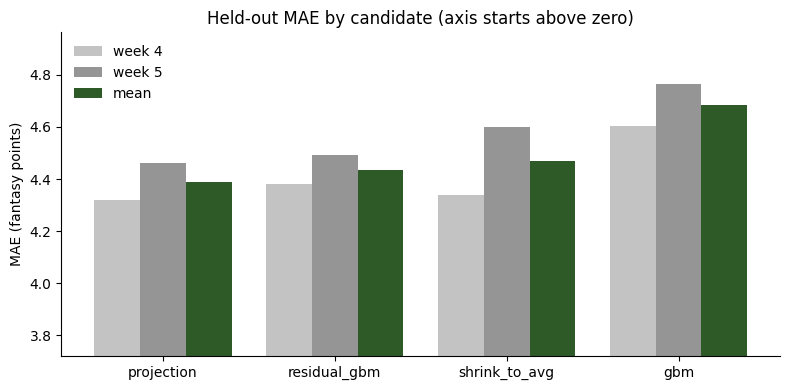

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(NAMES)); width = 0.8 / (len(test_weeks) + 1)
for i, w in enumerate(test_weeks):
    ax.bar(x + i * width, per_week.loc[w, NAMES], width, label=f'week {w}', color=plt.cm.Greys(0.35 + 0.15 * i))
ax.bar(x + len(test_weeks) * width, summary['mean across test weeks'], width, label='mean', color='#2d5a27')
ax.set_xticks(x + width * len(test_weeks) / 2); ax.set_xticklabels(NAMES)
lo = float(per_week[NAMES].min().min()); ax.set_ylim(lo - 0.6, float(per_week[NAMES].max().max()) + 0.2)
ax.set_ylabel('MAE (fantasy points)'); ax.set_title('Held-out MAE by candidate (axis starts above zero)'); ax.legend(frameon=False)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Are the differences real?

With a few hundred players per week the gaps are small. A paired bootstrap over the held-out player-weeks (resampling
rows, comparing each candidate's absolute error to the plain projection's on the same rows) shows how much of a gap
could be noise. A confidence interval that contains 0 means the candidate is not distinguishable from the projection.

In [9]:
rng = np.random.default_rng(0)
n = len(preds); idx = rng.integers(0, n, size=(2000, n))
rows = []
for k in NAMES[1:]:
    d = (preds['ae_' + k] - preds['ae_projection']).values          # positive = candidate is worse
    boots = d[idx].mean(1)
    rows.append(dict(candidate=k, mean_diff_vs_projection=d.mean(), ci_low=np.quantile(boots, 0.025), ci_high=np.quantile(boots, 0.975),
                     share_of_rows_better=(d < 0).mean()))
pd.DataFrame(rows).set_index('candidate').round(3)

,mean_diff_vs_projection,ci_low,ci_high,share_of_rows_better
candidate,,,,
residual_gbm,0.046,0.013,0.080,0.461
shrink_to_avg,0.077,0.023,0.132,0.472
gbm,0.293,0.183,0.408,0.403


## By position

Pooled MAE over all held-out player-weeks, with the number of rows. Note that DEF rows have no `gms_active` actuals in
Sleeper's weekly stats (the team-defense rows carry no `gms_active` flag), so team defenses never enter the evaluation (the app's engine applies the same rule).

In [10]:
bypos = preds.groupby('posname')[['ae_' + k for k in NAMES]].mean().rename(columns=lambda c: c[3:])
bypos['n'] = preds.groupby('posname').size()
bypos = bypos.reindex([p for p in POS if p in bypos.index])
bypos['best'] = bypos[NAMES].idxmin(axis=1)
bypos.round(3)

,projection,residual_gbm,shrink_to_avg,gbm,n,best
posname,,,,,,
QB,5.445,5.508,5.778,5.901,61,projection
RB,4.697,4.740,4.679,4.991,159,shrink_to_avg
WR,4.633,4.709,4.723,4.997,250,projection
TE,3.468,3.485,3.544,3.652,158,projection
K,3.920,3.911,3.934,4.041,62,residual_gbm


## Floor / ceiling coverage

The app's floors and ceilings are the 20th and 80th percentile of actual ÷ projected points per position (players
projected above 3 points). Out of sample: for each test week, fit those quantiles on **earlier weeks only** and count how often
the actual lands inside `[projection × q20, projection × q80]`. The target is 60%. As in the app, a position needs at least 25
training samples to be fitted; thinner positions are skipped here rather than given fallback constants.

In [11]:
def ratio_q(d):
    d = d[d.proj > 3]
    return {p: (float(np.quantile(g.y / g.proj, 0.2)), float(np.quantile(g.y / g.proj, 0.8))) for p, g in d.groupby('posname') if len(g) >= 25}

cov_rows = []
for tw in test_weeks:
    q = ratio_q(base[base.week < tw]); te = base[(base.week == tw) & (base.proj > 3) & base.posname.isin(q)]
    lo = te.proj * te.posname.map(lambda p: q[p][0]); hi = te.proj * te.posname.map(lambda p: q[p][1])
    inside = (te.y >= lo) & (te.y <= hi)
    cov_rows.append(dict(week=tw, n=len(te), coverage=inside.mean(), below_floor=(te.y < lo).mean(), above_ceiling=(te.y > hi).mean(),
                         **{f'cov_{p}': inside[te.posname == p].mean() for p in POS if p in q}))
cov = pd.DataFrame(cov_rows).set_index('week')
pooled = (cov.coverage * cov.n).sum() / cov.n.sum()
display(cov.round(3))
print(f'pooled coverage over test weeks: {pooled:.3f} (target 0.60)')
print('ratio quantiles fitted on all usable weeks:', {p: tuple(round(v, 2) for v in qq) for p, qq in ratio_q(base).items()})

,n,coverage,below_floor,above_ceiling,cov_QB,cov_RB,cov_WR,cov_TE,cov_K
week,,,,,,,,,
4,269,0.595,0.167,0.238,0.742,0.537,0.495,0.761,0.625
5,260,0.577,0.227,0.196,0.667,0.516,0.596,0.591,0.533


pooled coverage over test weeks: 0.586 (target 0.60)
ratio quantiles fitted on all usable weeks: {'K': (0.59, 1.69), 'QB': (0.69, 1.46), 'RB': (0.39, 1.44), 'TE': (0.28, 1.57), 'WR': (0.38, 1.61)}


## Does the plain projection still win?

Ranked by the mean across test weeks. The next cell prints the verdict from the numbers above, so the conclusion cannot drift
from the table when the notebook is re-run later in the season.

In [12]:
rank = summary['mean across test weeks'].sort_values()
winner = rank.index[0]
print('ranking (MAE):', {k: round(v, 3) for k, v in rank.items()})
print('winner:', winner)
print('plain projection wins' if winner == 'projection' else f'plain projection does NOT win: {winner} is lower by {rank["projection"] - rank[winner]:.3f} points')

ranking (MAE): {'projection': 4.39, 'residual_gbm': 4.436, 'shrink_to_avg': 4.468, 'gbm': 4.683}
winner: projection
plain projection wins


## Conclusion

**The plain Sleeper projection still wins.** Over the held-out weeks 4 and 5 (690 player-weeks) the mean MAE is
**4.39** for the projection, 4.44 for projection + 0.3 × GBM residual fix, 4.47 for shrink-to-season-average and 4.68 for
the gradient-boosting model on form, snap share and matchup. That is the original bake-off (4.39 / 4.43 / 4.47 / 4.68) to
within 0.01 on every line, using this league's own scoring and Sleeper's snap counts. The projection also wins in each
test week taken separately and in three of five position groups (shrink-to-average edges it for RBs by 0.02 and the residual GBM for kickers by 0.01,
differences too small to act on). The paired bootstrap says the gaps are real but small: the projection beats each
alternative, and the interval for every alternative sits above zero, but no tuned correction buys back more than a few
hundredths of a point. The full GBM is clearly worse, about 0.3 points per player-week.

**Keep the plain projection** as the player mean. Nothing in this run was tuned to protect that result: hyperparameters,
features and the candidate list are the reference notebook's.

**Floors and ceilings** (20th / 80th percentile of actual ÷ projected, fitted on earlier weeks): coverage is 59.5% for
week 4 and 57.7% for week 5, 58.6% pooled, against a 60% target. The weekly bands are slightly too narrow, and unevenly: QBs and TEs are
covered more often than RBs and WRs, which land between about 50% and 60%. That is a small, known miss, and the same 57.7% the original
run reported for week 5.

**Limits.** Only two weeks can be held out (the fixture has projections from week 2, and week 6 is in progress), so
these are the same two weeks as the original and the evidence is a small sample. Team defenses are not scored because
Sleeper's weekly stats give them no `gms_active` flag, so DEF floors and ceilings in the app use the fallback constants.
Re-run this notebook against a later fixture capture: it picks up every complete week automatically.

**Engine fix prompted by this notebook.** The finding above that team defenses have no `gms_active` led to a fix in `src/engine/model.ts`: a DEF stat line with `gp` > 0 now counts as played, so defenses get actual points, a locked current-week score, calibration samples and matchup grades. `buildModel(pull, { userId, referenceCompat: true })` keeps the old reference behavior for the regression test. This notebook's numbers are unaffected, because it does not use team-defense rows.